# Model Development & Student Profile Segmentation

## Student Social Profile Segmentation Using Clustering

Notebook ini membandingkan clustering pada 36 fitur minat hasil preprocessing, memilih model dengan mempertimbangkan metrik dan ukuran segmen, lalu memprofilkan hasilnya menggunakan fitur minat mentah dan metadata profil. Seluruh proses yang mengandung randomness memakai `random_state=42`.

## 1. Setup dan Pemuatan Data

Memuat representasi aktif `log1p`-scaled sebagai input utama, representasi biner untuk validasi bentuk data, matriks minat mentah untuk profiling, serta metadata profil bersih. Path dibangun relatif terhadap folder notebook sehingga tetap benar bila kernel dimulai dari root project atau folder `notebooks/`.

In [1]:
# Library yang dipakai di seluruh notebook
import os
os.environ["LOKY_MAX_CPU_COUNT"] = str(max(1, (os.cpu_count() or 1) - 1))

from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

# Seed yang sama dipakai di semua model supaya hasilnya bisa diulang
RANDOM_STATE = 42

# Tampilan grafik
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams["figure.titlesize"] = 14
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.mixture")

In [2]:
# Menentukan lokasi proyek (lokal, Colab, Kaggle, atau repo hasil git clone)
def find_project_root():
    cwd = Path.cwd()
    # Lokal: notebook dijalankan dari folder notebooks/, data ada di folder induknya
    if cwd.name == "notebooks" or (cwd.parent / "data").exists():
        return cwd.parent
    # Colab atau Kaggle: folder kerja sendiri berisi data/ atau outputs/
    if (cwd / "data").exists() or (cwd / "outputs").exists():
        return cwd
    # Repo hasil git clone ada satu level di bawah folder kerja
    for data_folder in sorted(cwd.glob("*/data")):
        return data_folder.parent
    return cwd


PROJECT_ROOT = find_project_root()

# Folder input (hasil data_preparation) dan folder output
PREPROCESSING_DIR = PROJECT_ROOT / "outputs" / "preprocessing"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
MODEL_DIR = PROJECT_ROOT / "outputs" / "models"
for directory in (FIGURE_DIR, TABLE_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

In [3]:
# Memuat hasil preprocessing dari notebook data_preparation
X_active_scaled = pd.read_csv(
    PREPROCESSING_DIR / "X_active_log1p_scaled.csv", index_col=0
)
X_active_binary = pd.read_csv(
    PREPROCESSING_DIR / "X_active_binary.csv", index_col=0
)
X_interest_raw = pd.read_csv(
    PREPROCESSING_DIR / "X_interest_raw.csv", index_col=0
)
profiles = pd.read_csv(
    PREPROCESSING_DIR / "student_profiles_clean.csv", index_col=0
)

In [4]:
# Memeriksa bahwa semua tabel sejajar (indeks dan kolom sama) sebelum dipakai
FEATURE_COLS = X_active_scaled.columns.tolist()
assert len(FEATURE_COLS) == 36
assert X_active_scaled.index.equals(X_active_binary.index)
assert X_active_scaled.columns.equals(X_active_binary.columns)
assert X_active_scaled.index.isin(X_interest_raw.index).all()
assert profiles.index.equals(X_interest_raw.index)
assert X_active_scaled.notna().all().all()

# Hitungan mentah untuk profil aktif, dipakai saat membuat profil klaster
X_active_raw = X_interest_raw.loc[X_active_scaled.index, FEATURE_COLS]

print(f"Data aktif untuk clustering: {X_active_scaled.shape[0]:,} baris x {len(FEATURE_COLS)} fitur")
print(f"Data biner validasi: {X_active_binary.shape}; profil lengkap: {profiles.shape}")
print("Fitur clustering:", FEATURE_COLS)

Data aktif untuk clustering: 13,762 baris x 36 fitur
Data biner validasi: (13762, 36); profil lengkap: (15000, 8)
Fitur clustering: ['basketball', 'football', 'soccer', 'softball', 'volleyball', 'swimming', 'cheerleading', 'baseball', 'tennis', 'sports', 'cute', 'sex', 'sexy', 'hot', 'kissed', 'dance', 'band', 'marching', 'music', 'rock', 'god', 'church', 'jesus', 'bible', 'hair', 'dress', 'blonde', 'mall', 'shopping', 'clothes', 'hollister', 'abercrombie', 'die', 'death', 'drunk', 'drugs']


**Interpretasi:** Hanya 36 fitur minat yang masuk ke ruang clustering. Atribut `gradyear`, `gender`, `age`, dan `NumberOffriends` disimpan untuk profiling setelah label terbentuk. Data biner dan data mentah disejajarkan melalui indeks profil; indeks CSV bukan fitur model.

## 2. Penentuan Jumlah Klaster K-Means

Elbow dan Silhouette dievaluasi untuk `k=2..10` pada kedua representasi (log1p-scaled dan binary) dengan sampel aktif acak tetap hingga 5.000 profil. Sampling membatasi biaya komputasi, terutama perhitungan Silhouette yang tumbuh kuadratik. Pilihan `k` untuk tiap representasi mengutamakan Silhouette dengan syarat setiap klaster mencakup setidaknya 2% sampel bila ada kandidat yang memenuhi.

In [5]:
# Subsampel tetap (seed sama) untuk memilih k supaya perhitungan tidak terlalu berat
K_SAMPLE_SIZE = min(5000, len(X_active_scaled))
X_k_selection = X_active_scaled.sample(
    n=K_SAMPLE_SIZE, random_state=RANDOM_STATE
).sort_index()
X_k_binary = X_active_binary.loc[X_k_selection.index]
SILHOUETTE_SAMPLE = min(2000, len(X_k_selection))

In [6]:
# Menjalankan K-Means untuk k = 2 sampai 10 pada dua representasi (log1p-scaled dan biner)
k_records = []
for k in range(2, 11):
    # Representasi log1p-scaled
    candidate = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = candidate.fit_predict(X_k_selection)
    counts = pd.Series(labels).value_counts(normalize=True)

    # Representasi biner
    binary_candidate = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    binary_labels = binary_candidate.fit_predict(X_k_binary)
    binary_counts = pd.Series(binary_labels).value_counts(normalize=True)

    k_records.append({
        "k": k,
        "inertia": candidate.inertia_,
        "silhouette": silhouette_score(
            X_k_selection, labels, sample_size=SILHOUETTE_SAMPLE,
            random_state=RANDOM_STATE
        ),
        "smallest_cluster_share": counts.min(),
        "binary_inertia": binary_candidate.inertia_,
        "binary_silhouette": silhouette_score(
            X_k_binary, binary_labels, sample_size=SILHOUETTE_SAMPLE,
            random_state=RANDOM_STATE
        ),
        "binary_smallest_cluster_share": binary_counts.min(),
    })

k_selection = pd.DataFrame(k_records)

In [7]:
# Memilih k: Silhouette tertinggi, dengan syarat klaster terkecil minimal 2% data
eligible_k = k_selection[k_selection["smallest_cluster_share"] >= 0.02]
selection_pool = eligible_k if not eligible_k.empty else k_selection
selected_k = int(
    selection_pool.sort_values(
        ["silhouette", "smallest_cluster_share"], ascending=[False, False]
    ).iloc[0]["k"]
)

# Aturan yang sama untuk representasi biner
eligible_binary_k = k_selection[k_selection["binary_smallest_cluster_share"] >= 0.02]
binary_selection_pool = eligible_binary_k if not eligible_binary_k.empty else k_selection
selected_k_binary = int(
    binary_selection_pool.sort_values(
        ["binary_silhouette", "binary_smallest_cluster_share"],
        ascending=[False, False],
    ).iloc[0]["k"]
)

k_selection.to_csv(TABLE_DIR / "k_selection_metrics.csv", index=False)
print(f"k terpilih log1p-scaled: {selected_k}; k terpilih binary: {selected_k_binary}.")

k terpilih log1p-scaled: 2; k terpilih binary: 2.


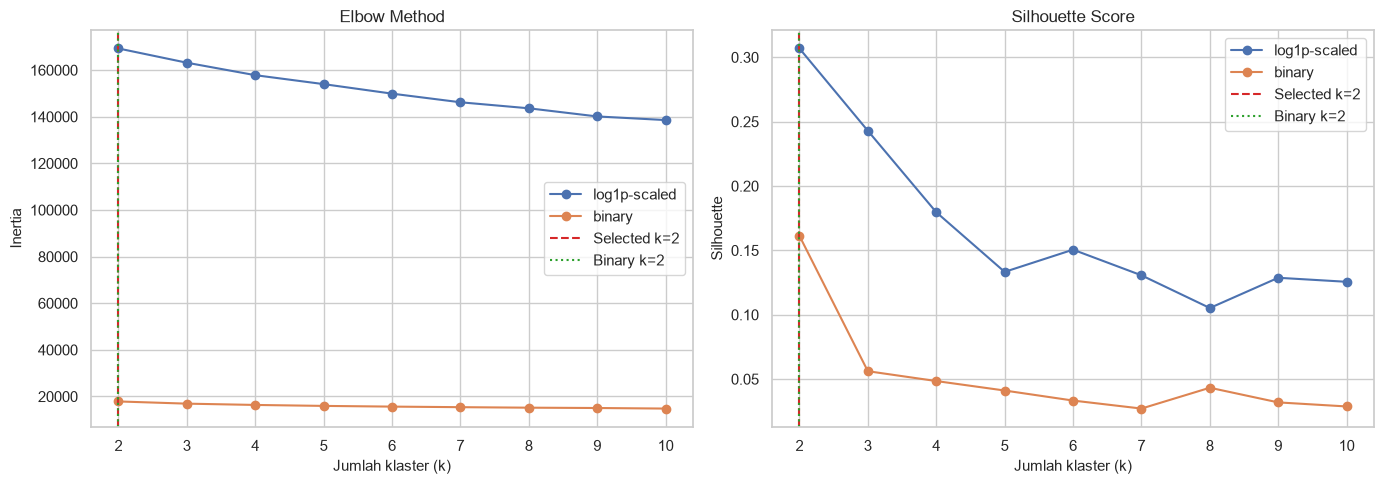

In [8]:
# Grafik elbow (inertia) dan Silhouette untuk k = 2 sampai 10
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_selection["k"], k_selection["inertia"], marker="o", label="log1p-scaled")
axes[0].plot(k_selection["k"], k_selection["binary_inertia"], marker="o", label="binary")
axes[0].axvline(selected_k, color="tab:red", linestyle="--", label=f"Selected k={selected_k}")
axes[0].axvline(selected_k_binary, color="tab:green", linestyle=":", label=f"Binary k={selected_k_binary}")
axes[0].set(title="Elbow Method", xlabel="Jumlah klaster (k)", ylabel="Inertia")
axes[0].legend()

axes[1].plot(k_selection["k"], k_selection["silhouette"], marker="o", label="log1p-scaled")
axes[1].plot(k_selection["k"], k_selection["binary_silhouette"], marker="o", label="binary")
axes[1].axvline(selected_k, color="tab:red", linestyle="--", label=f"Selected k={selected_k}")
axes[1].axvline(selected_k_binary, color="tab:green", linestyle=":", label=f"Binary k={selected_k_binary}")
axes[1].set(title="Silhouette Score", xlabel="Jumlah klaster (k)", ylabel="Silhouette")
axes[1].legend()

fig.tight_layout()
fig.savefig(FIGURE_DIR / "09_kmeans_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Tabel metrik pemilihan k
display(k_selection.round(4))
print("Pemilihan: Silhouette tertinggi, dengan preferensi ukuran minimum klaster >= 2%.")

,k,inertia,silhouette,smallest_cluster_share,binary_inertia,binary_silhouette,binary_smallest_cluster_share
0,2,169280.1512,0.3068,0.1338,17868.9351,0.1613,0.2874
1,3,163168.7486,0.2429,0.0334,16923.1774,0.0561,0.1870
2,4,157826.6495,0.1796,0.0336,16368.4237,0.0485,0.1476
3,5,153987.0684,0.1333,0.0334,15955.1512,0.0411,0.1128
4,6,149903.1629,0.1505,0.0330,15652.2267,0.0333,0.0994
5,7,146200.2406,0.1306,0.0332,15411.5966,0.0271,0.0932
6,8,143615.3130,0.1052,0.0330,15194.1926,0.0433,0.0572
7,9,140121.5084,0.1287,0.0140,15054.4866,0.0319,0.0572
8,10,138569.5477,0.1256,0.0142,14812.3930,0.0287,0.0500


Pemilihan: Silhouette tertinggi, dengan preferensi ukuran minimum klaster >= 2%.


**Interpretasi:** Bandingkan kurva kedua representasi bersama-sama. Inertia selalu turun ketika `k` bertambah, sehingga elbow bukan bukti tunggal. `k` dipilih per representasi melalui Silhouette tertinggi dengan preferensi ukuran minimum klaster >=2%; keputusan akhir tetap mempertimbangkan interpretabilitas dan keseimbangan segmen.

## 3. Pembandingan Algoritma dan Diagnostik Jarak

K-Means pada kedua representasi, Ward Agglomerative, DBSCAN, dan diagonal-covariance GMM dibandingkan pada sampel aktif deterministik. Agglomerative dan DBSCAN bersifat eksploratif; model final dipilih dari K-Means/GMM karena keduanya dapat menghasilkan assignment untuk seluruh profil aktif. Dendrogram dihitung pada subset 1.000 titik untuk menjaga biaya kuadratik tetap terkendali. `eps` DBSCAN ditaksir dari titik siku kurva jarak ke tetangga ke-10; noise dilaporkan terpisah.

In [10]:
# Sampel tetap untuk membandingkan semua algoritma pada data yang sama
COMPARISON_SAMPLE_SIZE = min(2500, len(X_active_scaled))
X_model = X_active_scaled.sample(
    n=COMPARISON_SAMPLE_SIZE, random_state=RANDOM_STATE
).sort_index()
X_binary_model = X_active_binary.loc[X_model.index]

# K-Means pada data log1p-scaled (ini yang menjadi baseline)
kmeans_sample = KMeans(
    n_clusters=selected_k, n_init=10, random_state=RANDOM_STATE
)
labels_kmeans = kmeans_sample.fit_predict(X_model)

# K-Means pada data biner
kmeans_binary_sample = KMeans(
    n_clusters=selected_k_binary, n_init=10, random_state=RANDOM_STATE
)
labels_kmeans_binary = kmeans_binary_sample.fit_predict(X_binary_model)

print(f"Sampel pembanding: {len(X_model):,}; k={selected_k}")

Sampel pembanding: 2,500; k=2


In [11]:
# Agglomerative clustering dengan linkage Ward pada data log1p-scaled
agglomerative = AgglomerativeClustering(n_clusters=selected_k, linkage="ward")
labels_agglomerative = agglomerative.fit_predict(X_model)

In [12]:
# DBSCAN: eps ditentukan dari titik knee pada kurva k-distance
MIN_SAMPLES = 10
neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES, n_jobs=1)
neighbor_distances, _ = neighbors.fit(X_model).kneighbors(X_model)

# Jarak ke tetangga ke-10, diurutkan dari kecil ke besar
k_distances = np.sort(neighbor_distances[:, -1])
positive_k_distances = k_distances[k_distances > 1e-4]
if positive_k_distances.size == 0:
    raise ValueError("Tidak ada jarak k-neighbor positif untuk menentukan eps DBSCAN.")

# Knee = titik dengan selisih terbesar antara kurva dan garis lurus awal-akhir
normalized_x = np.linspace(0, 1, len(positive_k_distances))
distance_range = np.ptp(positive_k_distances)
normalized_y = (positive_k_distances - positive_k_distances.min()) / distance_range
knee_index = int(np.argmax(normalized_y - normalized_x))
EPS_ESTIMATE = float(positive_k_distances[knee_index])

# eps diambil dari knee lalu dibulatkan ke atas 2 desimal. Nilai knee jatuh tepat pada jarak antar titik,
# sehingga kalau dipakai apa adanya hasil DBSCAN bisa berbeda antar komputer.
EPS_USED = float(np.ceil(EPS_ESTIMATE * 100) / 100)
dbscan = DBSCAN(eps=EPS_USED, min_samples=MIN_SAMPLES, n_jobs=1)
labels_dbscan = dbscan.fit_predict(X_model)

print(f"DBSCAN eps={EPS_USED:.2f} (knee {EPS_ESTIMATE:.4f}), min_samples={MIN_SAMPLES}")
print("Label DBSCAN:", pd.Series(labels_dbscan).value_counts().sort_index().to_dict())

DBSCAN eps=1.37 (knee 1.3633), min_samples=10
Label DBSCAN: {-1: 2200, 0: 18, 1: 24, 2: 12, 3: 17, 4: 15, 5: 13, 6: 59, 7: 11, 8: 16, 9: 21, 10: 35, 11: 25, 12: 15, 13: 19}


In [13]:
# Gaussian Mixture dengan kovarians diagonal pada data log1p-scaled
gmm = GaussianMixture(
    n_components=selected_k, covariance_type="diag", n_init=1,
    max_iter=150, reg_covar=1e-4, random_state=RANDOM_STATE
)
labels_gmm = gmm.fit_predict(X_model)

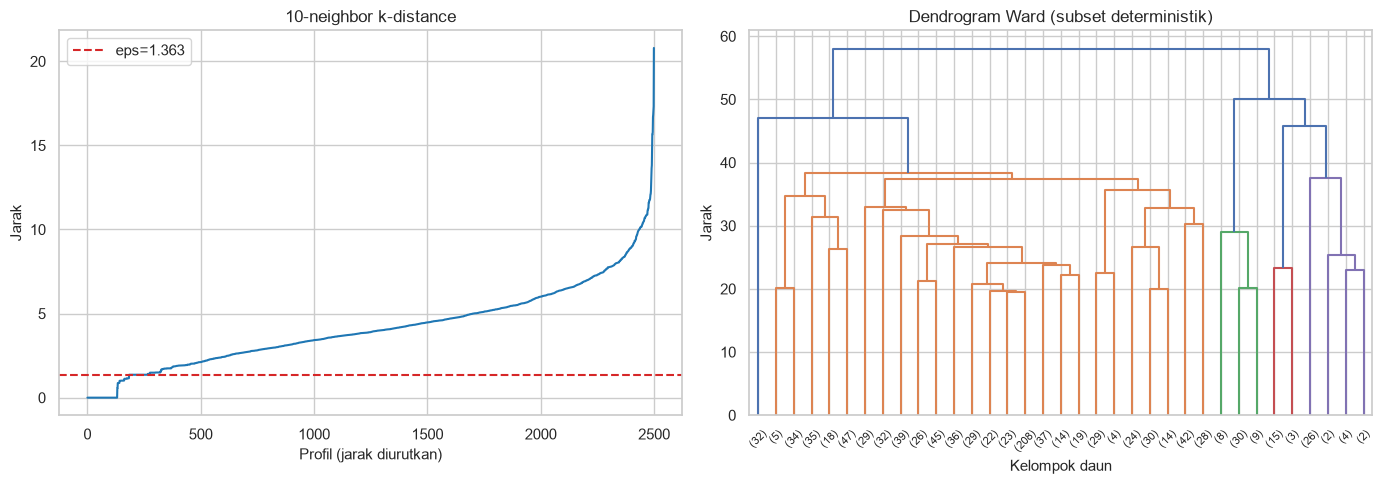

In [14]:
# Grafik diagnostik: kurva k-distance untuk DBSCAN dan dendrogram Ward
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_distances, color="tab:blue")
axes[0].axhline(EPS_ESTIMATE, color="tab:red", linestyle="--", label=f"eps={EPS_ESTIMATE:.3f}")
axes[0].set(title=f"{MIN_SAMPLES}-neighbor k-distance", xlabel="Profil (jarak diurutkan)", ylabel="Jarak")
axes[0].legend()

# Dendrogram memakai subset 1.000 profil supaya tetap bisa dibaca
dendrogram_sample = X_model.sample(
    n=min(1000, len(X_model)), random_state=RANDOM_STATE
).sort_index()
hierarchy = linkage(dendrogram_sample, method="ward")
dendrogram(hierarchy, ax=axes[1], truncate_mode="lastp", p=35, show_leaf_counts=True)
axes[1].set(title="Dendrogram Ward (subset deterministik)", xlabel="Kelompok daun", ylabel="Jarak")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "10_density_and_dendrogram.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretasi:** Dendrogram hanya merangkum struktur subset, bukan seluruh 13.762 profil. `eps` DBSCAN adalah estimasi kurva jarak dan hasilnya perlu dinilai dari jumlah klaster, persentase noise, serta metrik pada inlier. DBSCAN yang menghasilkan satu klaster atau semua noise tidak memiliki Silhouette yang valid.

## 4. Evaluasi dan Pemilihan Model

Metrik dihitung pada hasil fit di sampel pembanding: Silhouette dan Calinski–Harabasz lebih tinggi umumnya lebih baik, Davies–Bouldin lebih rendah lebih baik. Baris DBSCAN dievaluasi hanya pada inlier dan menyertakan coverage/noise agar keterbatasan tersebut terlihat. Untuk pemilihan model yang akan memberi label ke seluruh data, K-Means dan GMM dirangking dari ketiga metrik; Agglomerative dan DBSCAN tetap menjadi pembanding eksploratif.

In [15]:
# Fungsi untuk menghitung tiga metrik internal
def clustering_metrics(X, labels):
    labels = np.asarray(labels)
    unique_labels = np.unique(labels)
    # Metrik tidak bisa dihitung kalau klasternya kurang dari 2 atau tiap titik jadi klaster sendiri
    if len(unique_labels) < 2 or len(unique_labels) >= len(labels):
        return np.nan, np.nan, np.nan
    return (
        silhouette_score(X, labels),
        davies_bouldin_score(X, labels),
        calinski_harabasz_score(X, labels),
    )


# Daftar model: nama, label hasil clustering, dan titik yang ikut dihitung
# (DBSCAN hanya dihitung pada inlier karena noise tidak punya klaster)
all_points = np.ones(len(X_model), dtype=bool)
comparison_specs = [
    ("K-Means (log1p-scaled)", labels_kmeans, all_points),
    ("K-Means (binary)", labels_kmeans_binary, all_points),
    ("Agglomerative Ward", labels_agglomerative, all_points),
    ("DBSCAN", labels_dbscan, labels_dbscan != -1),
    ("Gaussian Mixture (diag, log1p-scaled)", labels_gmm, all_points),
]

In [16]:
# Menghitung metrik tiap model pada sampel yang sama (ruang log1p-scaled)
comparison_records = []
for model_name, labels, metric_mask in comparison_specs:
    metric_labels = labels[metric_mask]
    metric_X = X_model.loc[metric_mask]
    silhouette, db_index, ch_index = clustering_metrics(metric_X, metric_labels)
    cluster_sizes_sample = pd.Series(labels[labels != -1]).value_counts(normalize=True)
    comparison_records.append({
        "model": model_name,
        "role": "Baseline" if model_name == "K-Means (log1p-scaled)" else "Kandidat",
        "clusters_excluding_noise": len(np.unique(labels[labels != -1])),
        "noise_share": float(np.mean(labels == -1)),
        "smallest_cluster_share": float(cluster_sizes_sample.min()) if len(cluster_sizes_sample) else np.nan,
        "silhouette": silhouette,
        "davies_bouldin": db_index,
        "calinski_harabasz": ch_index,
        "metric_profiles": int(metric_mask.sum()),
        "metric_scope": "inliers only" if model_name == "DBSCAN" else "full comparison sample",
    })

model_comparison = pd.DataFrame(comparison_records)

In [17]:
# Memilih model yang bisa memberi label ke seluruh data (K-Means dan GMM),
# berdasarkan rata-rata peringkat tiga metrik
deployable = model_comparison[model_comparison["model"].isin([
    "K-Means (log1p-scaled)", "K-Means (binary)",
    "Gaussian Mixture (diag, log1p-scaled)",
])].copy()
for metric, ascending in [
    ("silhouette", False),
    ("davies_bouldin", True),
    ("calinski_harabasz", False),
]:
    deployable[f"{metric}_rank"] = deployable[metric].rank(ascending=ascending, method="average")
deployable["mean_metric_rank"] = deployable[
    ["silhouette_rank", "davies_bouldin_rank", "calinski_harabasz_rank"]
].mean(axis=1)
deployable = deployable.sort_values(
    ["mean_metric_rank", "silhouette", "smallest_cluster_share"],
    ascending=[True, False, False],
)

best_algorithm = deployable.iloc[0]["model"]
best_feature_representation = (
    "binary" if best_algorithm == "K-Means (binary)" else "log1p_scaled"
)
model_comparison.to_csv(TABLE_DIR / "model_comparison.csv", index=False)

In [18]:
# Tabel perbandingan model
display(model_comparison.round(4))
print("Model assignment penuh terpilih:", best_algorithm)
print("Pemilihan memakai rerata peringkat tiga metrik pada K-Means/GMM yang bisa memberi label penuh.")

,model,role,clusters_excluding_noise,noise_share,smallest_cluster_share,silhouette,davies_bouldin,calinski_harabasz,metric_profiles,metric_scope
0,K-Means (log1p-scaled),Baseline,2,0.00,0.1448,0.3025,3.2524,157.2216,2500,full comparison sample
1,K-Means (binary),Kandidat,2,0.00,0.2964,0.1652,4.0514,127.1706,2500,full comparison sample
2,Agglomerative Ward,Kandidat,2,0.00,0.0212,0.4493,1.9042,99.9252,2500,full comparison sample
3,DBSCAN,Kandidat,14,0.88,0.0367,0.6268,0.5828,109.0548,300,inliers only
4,"Gaussian Mixture (diag, log1p-scaled)",Kandidat,2,0.00,0.1872,0.2402,3.9331,117.9022,2500,full comparison sample


Model assignment penuh terpilih: K-Means (log1p-scaled)
Pemilihan memakai rerata peringkat tiga metrik pada K-Means/GMM yang bisa memberi label penuh.


**Interpretasi:** Pilihan akhir adalah model dengan rerata peringkat terbaik di antara model yang dapat menetapkan label untuk data baru. Kualitas metrik tidak cukup bila segmen terlalu kecil atau tidak dapat dijelaskan; periksa ukuran segmen dan profil pada tahap berikutnya. DBSCAN dinilai hanya pada inlier sehingga nilainya tidak sebanding langsung dengan model lain ketika noise besar.

## 5–7. Fit Penuh, Visualisasi, Profiling, dan Penyimpanan

Model terpilih di-fit ulang pada seluruh profil aktif. Profil tanpa minat tercatat diberi `cluster_id=0` sebagai segmen deskriptif terpisah; label model aktif digeser menjadi 1..k agar tidak berbenturan. PCA dipakai hanya untuk visualisasi 2D—bukan sebagai input model. Statistik profil menggunakan hitungan minat mentah agar mudah ditafsirkan.

In [19]:
# Fit model terpilih pada seluruh profil aktif (bukan hanya sampel)
if best_algorithm == "K-Means (log1p-scaled)":
    best_model = KMeans(
        n_clusters=selected_k, n_init=10, random_state=RANDOM_STATE
    ).fit(X_active_scaled)
    active_labels = best_model.labels_
    best_cluster_count = selected_k
elif best_algorithm == "K-Means (binary)":
    best_model = KMeans(
        n_clusters=selected_k_binary, n_init=10, random_state=RANDOM_STATE
    ).fit(X_active_binary)
    active_labels = best_model.labels_
    best_cluster_count = selected_k_binary
else:
    best_model = GaussianMixture(
        n_components=selected_k, covariance_type="diag", n_init=1,
        max_iter=150, reg_covar=1e-4, random_state=RANDOM_STATE
    ).fit(X_active_scaled)
    active_labels = best_model.predict(X_active_scaled)
    best_cluster_count = selected_k

In [20]:
# Menggabungkan label ke seluruh profil: profil all-zero otomatis jadi klaster 0,
# label model dimulai dari 1
clustered_data = profiles.join(X_interest_raw)
clustered_data["cluster_id"] = 0
clustered_data.loc[X_active_scaled.index, "cluster_id"] = active_labels + 1
clustered_data["cluster_id"] = clustered_data["cluster_id"].astype(int)

# Pemeriksaan: tidak ada profil yang hilang, profil aktif tidak ada di klaster 0
assert len(clustered_data) == len(profiles)
assert (clustered_data.loc[X_active_scaled.index, "cluster_id"] > 0).all()
assert (clustered_data.loc[~X_interest_raw.index.isin(X_active_scaled.index), "cluster_id"] == 0).all()

cluster_sizes = clustered_data["cluster_id"].value_counts().sort_index()

In [21]:
# Ringkasan ukuran klaster dan rata-rata/median tiap fitur minat
cluster_summary = pd.DataFrame({
    "cluster_id": cluster_sizes.index,
    "cluster_size": cluster_sizes.values,
    "proportion": (cluster_sizes / len(clustered_data)).values,
})
interest_means = clustered_data.groupby("cluster_id")[FEATURE_COLS].mean()
interest_medians = clustered_data.groupby("cluster_id")[FEATURE_COLS].median()
interest_means.columns = [f"mean_{name}" for name in interest_means.columns]
interest_medians.columns = [f"median_{name}" for name in interest_medians.columns]

# Statistik atribut profil per klaster (hanya untuk interpretasi, bukan input clustering)
profile_stats = clustered_data.groupby("cluster_id").agg(
    mean_gradyear=("gradyear", "mean"), median_gradyear=("gradyear", "median"),
    mean_age_imputed=("age_imputed", "mean"), median_age_imputed=("age_imputed", "median"),
    mean_friends=("NumberOffriends", "mean"), median_friends=("NumberOffriends", "median"),
    mean_total_interest_counts=("total_interests", "mean"),
    median_total_interest_counts=("total_interests", "median"),
)

# Tabel profil klaster dan komposisi gender
cluster_profile = cluster_summary.set_index("cluster_id").join(profile_stats)
cluster_profile = cluster_profile.join(interest_means).join(interest_medians).reset_index()
gender_profile = pd.crosstab(
    clustered_data["cluster_id"], clustered_data["gender_clean"], normalize="index"
).rename_axis(index="cluster_id").reset_index()

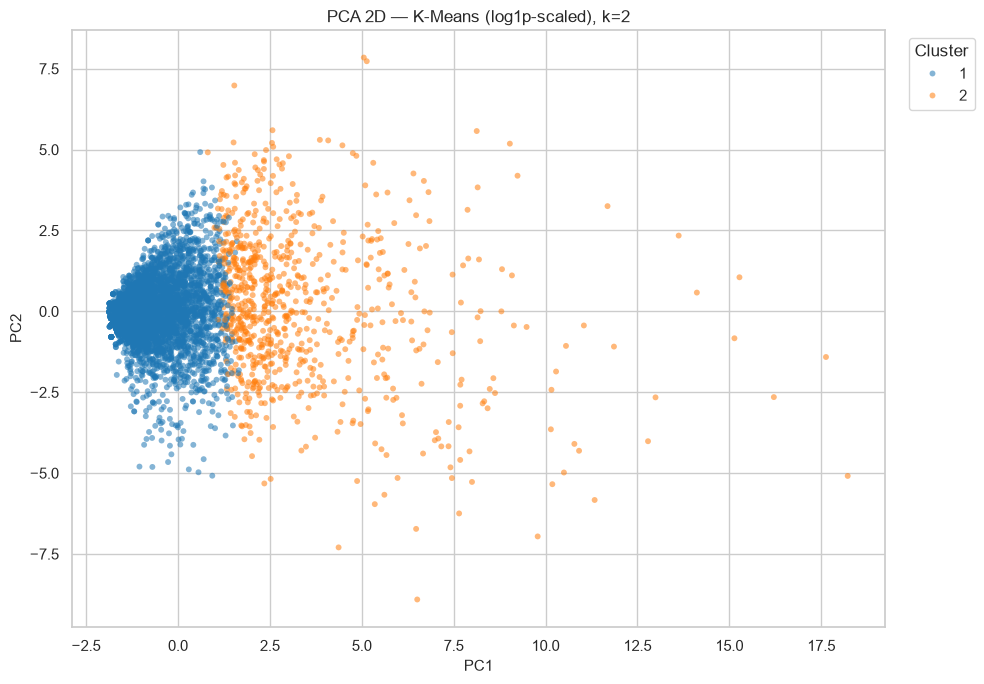

In [22]:
# Proyeksi PCA 2 komponen untuk visualisasi klaster
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_coordinates = pca.fit_transform(X_active_scaled)
pca_frame = pd.DataFrame({
    "PC1": pca_coordinates[:, 0], "PC2": pca_coordinates[:, 1],
    "cluster_id": active_labels + 1,
}, index=X_active_scaled.index)

# Plot memakai sampel 5.000 titik supaya tidak terlalu padat
pca_plot = pca_frame.sample(
    n=min(5000, len(pca_frame)), random_state=RANDOM_STATE
)
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=pca_plot, x="PC1", y="PC2", hue="cluster_id", palette="tab10",
    alpha=0.55, s=18, linewidth=0, ax=ax,
)
ax.set_title(f"PCA 2D — {best_algorithm}, k={best_cluster_count}")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "11_best_model_pca_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

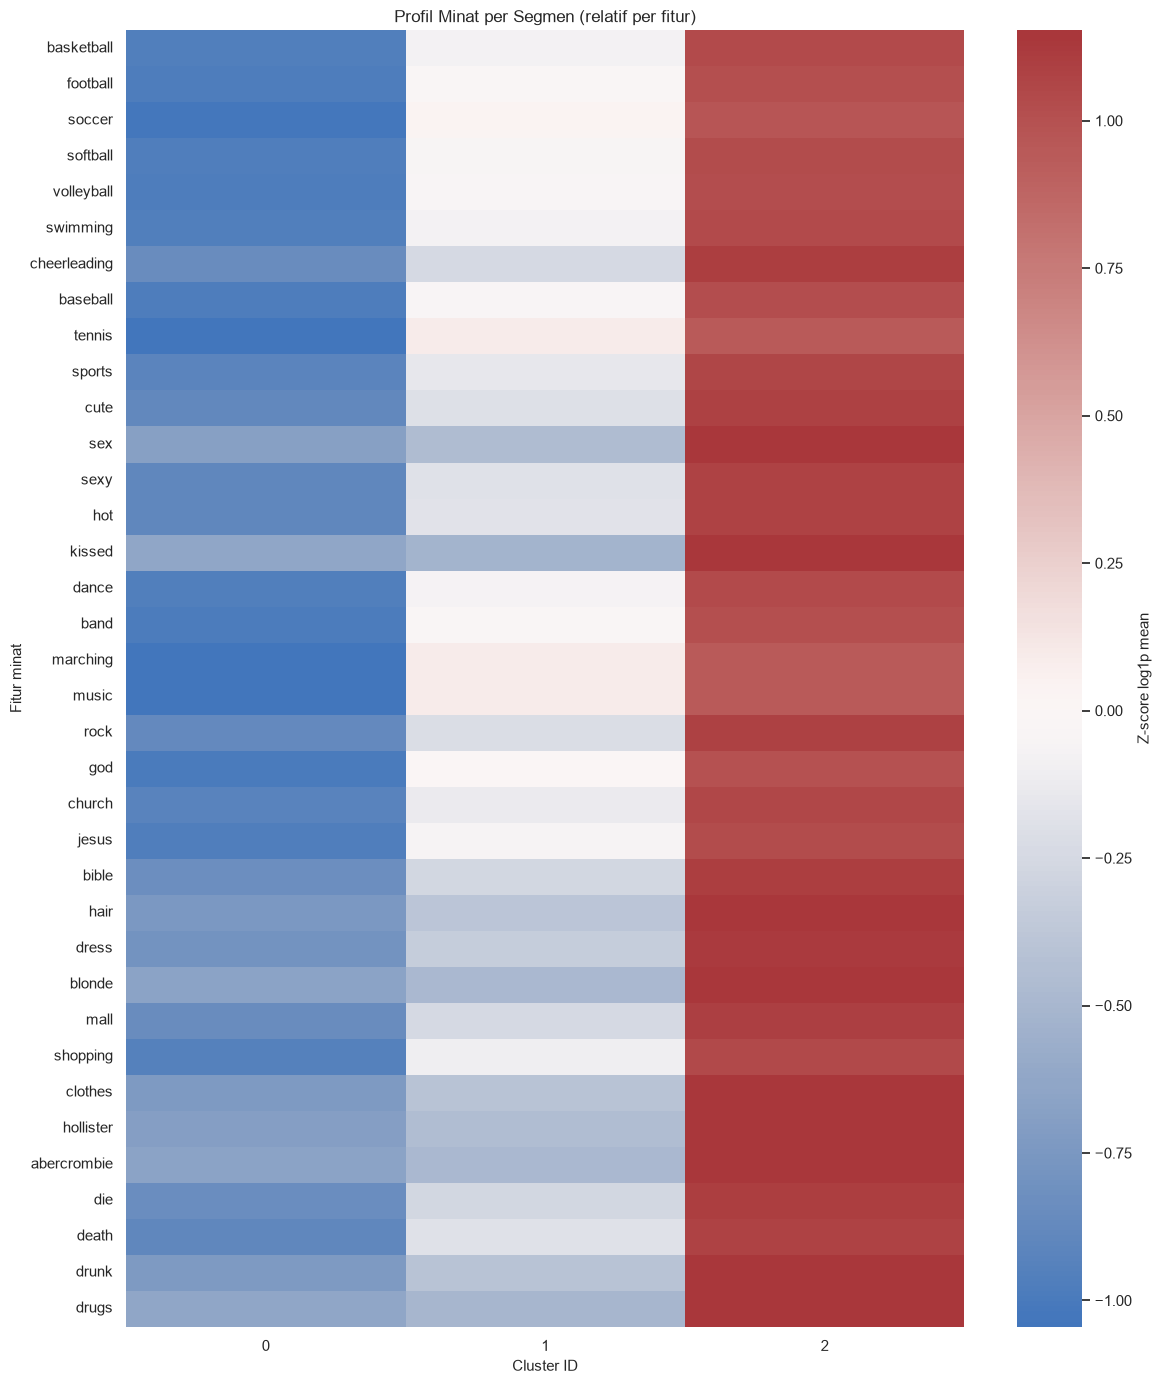

In [23]:
# Heatmap profil minat per klaster: rata-rata log1p, lalu di-z-score per fitur
mean_matrix = interest_means.copy()
mean_matrix.columns = FEATURE_COLS
heatmap_values = np.log1p(mean_matrix).T
heatmap_values = heatmap_values.sub(heatmap_values.mean(axis=1), axis=0)
heatmap_values = heatmap_values.div(heatmap_values.std(axis=1).replace(0, 1), axis=0)

fig, ax = plt.subplots(figsize=(12, 14))
sns.heatmap(heatmap_values, cmap="vlag", center=0, ax=ax, cbar_kws={"label": "Z-score log1p mean"})
ax.set(title="Profil Minat per Segmen (relatif per fitur)", xlabel="Cluster ID", ylabel="Fitur minat")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "12_cluster_interest_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

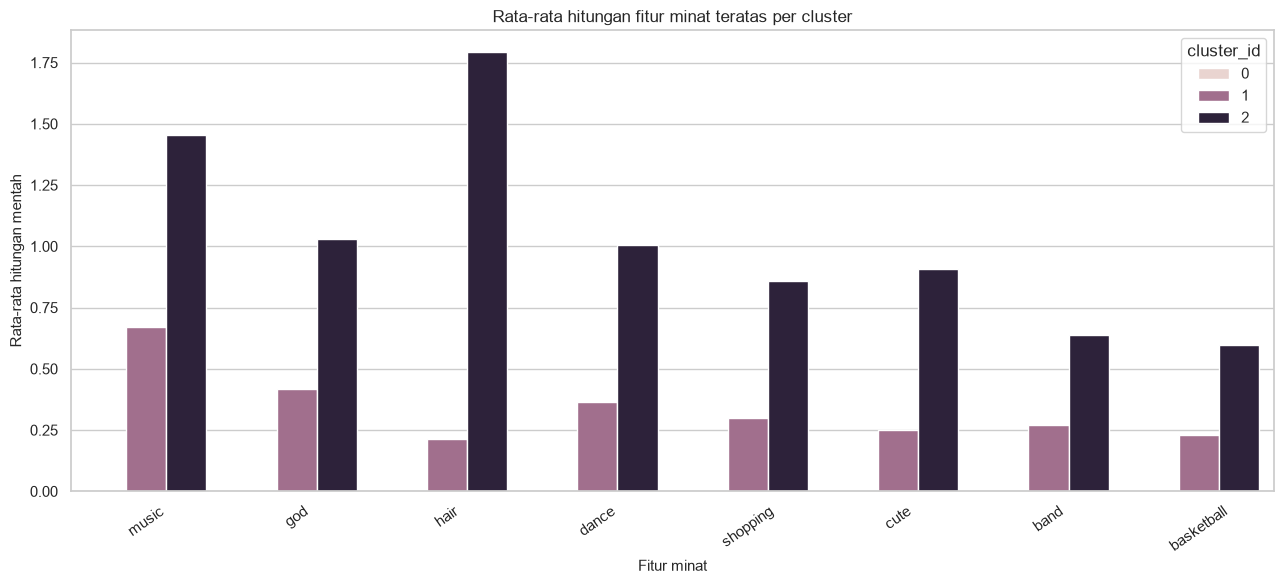

In [24]:
# Rata-rata hitungan mentah untuk 8 fitur minat paling sering muncul, per klaster
top_features = X_active_raw.mean().sort_values(ascending=False).head(8).index.tolist()
bar_data = clustered_data.groupby("cluster_id")[top_features].mean().reset_index().melt(
    id_vars="cluster_id", var_name="interest", value_name="mean_count"
)

fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(data=bar_data, x="interest", y="mean_count", hue="cluster_id", ax=ax)
ax.set(title="Rata-rata hitungan fitur minat teratas per cluster", xlabel="Fitur minat", ylabel="Rata-rata hitungan mentah")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "13_cluster_top_interest_means.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
# Memberi deskripsi singkat tiap segmen dari tiga fitur dengan rata-rata tertinggi
cluster_names = {0: "No recorded interests"}
for cluster_id in sorted(set(active_labels + 1)):
    means = clustered_data.loc[clustered_data["cluster_id"] == cluster_id, FEATURE_COLS].mean()
    top_three = means.sort_values(ascending=False).head(3).index.tolist()
    cluster_names[int(cluster_id)] = "Minat tercatat: " + ", ".join(top_three)
cluster_profile["segment_description"] = cluster_profile["cluster_id"].map(cluster_names)
clustered_data["segment_description"] = clustered_data["cluster_id"].map(cluster_names)

In [26]:
# Menyimpan tabel hasil dan model beserta metadatanya
cluster_profile.to_csv(TABLE_DIR / "cluster_profile_summary.csv", index=False)
gender_profile.to_csv(TABLE_DIR / "cluster_gender_profile.csv", index=False)
clustered_data.to_csv(TABLE_DIR / "clustered_student_profiles.csv", index=True)

model_bundle = {
    "model": best_model,
    "algorithm": best_algorithm,
    "n_clusters_active": best_cluster_count,
    "random_state": RANDOM_STATE,
    "feature_names": FEATURE_COLS,
    "feature_representation": best_feature_representation,
    "active_label_offset": 1,
    "all_zero_cluster_id": 0,
}
joblib.dump(model_bundle, MODEL_DIR / "best_clustering_model.joblib")
print("Tabel hasil dan model tersimpan di folder outputs/")


Tabel hasil dan model tersimpan di folder outputs/


In [27]:
# Ringkasan profil klaster
display(cluster_profile[[
    "cluster_id", "cluster_size", "proportion", "mean_age_imputed",
    "median_age_imputed", "mean_friends", "median_friends",
    "mean_total_interest_counts", "segment_description",
]].round(3))

,cluster_id,cluster_size,proportion,mean_age_imputed,median_age_imputed,mean_friends,median_friends,mean_total_interest_counts,segment_description
0,0,1238,0.083,17.403,17.659,17.907,4.0,0.000,No recorded interests
1,1,11523,0.768,17.283,17.303,29.537,20.0,5.564,"Minat tercatat: music, god, dance"
2,2,2239,0.149,17.004,16.802,37.960,27.0,19.262,"Minat tercatat: hair, music, god"


In [28]:
# Komposisi gender per klaster dan informasi model
display(gender_profile.round(3))
print(f"Model final: {best_algorithm}; k aktif={best_cluster_count}; profil berlabel={len(clustered_data):,}")
print("Proporsi varians PCA:", np.round(pca.explained_variance_ratio_, 4).tolist())
print("Ukuran klaster:", cluster_sizes.to_dict())

gender_clean,cluster_id,F,M,Unknown
0,0,0.523,0.230,0.247
1,1,0.735,0.186,0.079
2,2,0.867,0.079,0.054


Model final: K-Means (log1p-scaled); k aktif=2; profil berlabel=15,000
Proporsi varians PCA: [0.0963, 0.0483]
Ukuran klaster: {0: 1238, 1: 11523, 2: 2239}


In [29]:
# Perbandingan rata-rata hitungan tiap topik antara klaster aktif dengan minat banyak dan minat sedikit
# (dipakai untuk membaca arti klaster, hanya berlaku kalau model akhir punya 2 klaster aktif)
if best_cluster_count == 2:
    profile_by_id = cluster_profile.set_index("cluster_id")
    active_ids = profile_by_id.drop(index=0)["mean_total_interest_counts"]
    high_id, low_id = active_ids.idxmax(), active_ids.idxmin()

    mean_cols = [f"mean_{name}" for name in FEATURE_COLS]
    topic_ratio = profile_by_id.loc[high_id, mean_cols] / profile_by_id.loc[low_id, mean_cols]
    topic_ratio.index = FEATURE_COLS

    print(f"Klaster minat banyak: {high_id}; klaster minat sedikit: {low_id}")
    print(f"Topik dengan rata-rata lebih tinggi di klaster {high_id}: {(topic_ratio > 1).sum()} dari {len(topic_ratio)}")
    print(f"Rasio rata-rata klaster {high_id} terhadap klaster {low_id}: terkecil {topic_ratio.min():.1f}, terbesar {topic_ratio.max():.1f}")
    display(topic_ratio.sort_values(ascending=False).head(5).round(1).to_frame("rasio"))

Klaster minat banyak: 2; klaster minat sedikit: 1
Topik dengan rata-rata lebih tinggi di klaster 2: 36 dari 36
Rasio rata-rata klaster 2 terhadap klaster 1: terkecil 1.8, terbesar 20.4


,rasio
kissed,20.4
drugs,15.9
blonde,12.7
abercrombie,11.5
sex,11.2


**Interpretasi segmen:** Deskripsi segmen aktif dibuat dari tiga fitur minat mentah dengan rata-rata tertinggi di segmen tersebut; deskripsi ini merangkum sinyal data, bukan label demografis atau klaim tentang individu. Klaster 0 berarti tidak ada minat yang tercatat pada 36 fitur. Gunakan ukuran/proposi, statistik usia dan teman, komposisi gender, heatmap relatif, dan PCA secara bersamaan. PCA hanya proyeksi visual dan tidak membuktikan pemisahan klaster di ruang fitur penuh.

**Arti tiap klaster (model k=2, dibaca bersama tabel profil, heatmap, dan PCA):**

- **Klaster 0 (1.238 profil, 8,25%): profil tanpa minat tercatat.** Seluruh 36 fitur bernilai 0, median teman hanya 4, dan 24,7% gendernya Unknown. Ini profil yang tidak menuliskan kata kunci minat apa pun, bisa karena akun pasif atau profil yang tidak diisi. Artinya bukan bahwa siswanya tidak punya minat.
- **Klaster 1 (11.523 profil, 76,82%): minat sedikit sampai sedang.** Median total minat 5 dan median teman 20. Topik yang paling sering muncul adalah `music`, `god`, dan `dance`, yaitu topik yang juga paling umum di seluruh data, jadi klaster ini tidak punya topik yang menonjol.
- **Klaster 2 (2.239 profil, 14,93%): minat banyak, profil aktif.** Median total minat 16, median teman 27, dan 86,7% perempuan. Rata-rata hitungan lebih tinggi daripada klaster 1 pada semua 36 topik (1,8 sampai 20,4 kali), paling besar pada `kissed`, `drugs`, dan `blonde`. Klaster ini dibedakan oleh banyaknya minat yang ditulis, bukan oleh satu topik khusus.

Jadi tiga segmen ini dapat dibaca sebagai tiga tingkat banyaknya minat yang tercatat: tidak ada, sedang, dan banyak. Perbedaan jumlah teman dan komposisi gender hanya gambaran deskriptif dan tidak menunjukkan hubungan sebab-akibat. Arti berbasis topik baru terlihat pada analisis k=3 sampai 5 di bagian berikutnya.

## 8. Analisis Sensitivitas Jumlah Klaster (k=3 sampai 5)

Pemilihan k=2 didasarkan pada Silhouette, tetapi Silhouette cenderung menyukai pembagian paling kasar. Bagian ini hanya melihat isi klaster pada k=3, 4, dan 5 dengan representasi `log1p`-scaled yang sama. Ini analisis tambahan untuk membaca struktur data, bukan pemilihan model, sehingga model akhir sementara tetap K-Means k=2. Profil tiap klaster diringkas dengan ukuran, median total minat per profil, dan empat fitur dengan rata-rata z-score tertinggi.

In [30]:
# Total minat per profil aktif, dan seberapa besar pembagian k=2 hanya mencerminkan jumlah minat
total_minat = X_active_raw.sum(axis=1)
km_baseline = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit(X_active_scaled)
corr_total = abs(np.corrcoef(km_baseline.labels_, total_minat)[0, 1])
print(f"Korelasi label k=2 dengan total minat per profil: {corr_total:.3f}")
for cluster in (0, 1):
    members = km_baseline.labels_ == cluster
    print(f"  klaster {cluster}: {members.sum():,} profil, median total minat {total_minat[members].median():.0f}")

Korelasi label k=2 dengan total minat per profil: 0.626
  klaster 0: 11,523 profil, median total minat 5
  klaster 1: 2,239 profil, median total minat 16


In [31]:
# Menjalankan K-Means pada k = 3, 4, 5 lalu meringkas isi tiap klaster
sensitivity_rows = []
for k in (3, 4, 5):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_active_scaled)
    labels_k = pd.Series(km_k.labels_, index=X_active_scaled.index)
    for cluster in sorted(labels_k.unique()):
        members = labels_k == cluster
        # Empat fitur dengan rata-rata z-score tertinggi di klaster ini
        mean_z = X_active_scaled.loc[members].mean().sort_values(ascending=False)
        sensitivity_rows.append({
            "k": k,
            "cluster": int(cluster),
            "size": int(members.sum()),
            "share_pct": round(members.mean() * 100, 1),
            "median_total_interests": float(total_minat[members].median()),
            "top_features": ", ".join(mean_z.index[:4]),
            "top_feature_mean_z": round(float(mean_z.iloc[0]), 2),
        })

k_sensitivity = (
    pd.DataFrame(sensitivity_rows)
    .sort_values(["k", "size"], ascending=[True, False])
    .reset_index(drop=True)
)
k_sensitivity.to_csv(TABLE_DIR / "k_sensitivity_profiles.csv", index=False)

In [32]:
# Tabel profil klaster pada k = 3, 4, 5
display(k_sensitivity)

,k,cluster,size,share_pct,median_total_interests,top_features,top_feature_mean_z
0,3,0,9570,69.5,4.0,"marching, band, tennis, sexy",-0.01
1,3,1,3429,24.9,12.0,"shopping, church, cute, hollister",0.68
2,3,2,763,5.5,21.0,"kissed, sex, drugs, hair",2.52
3,4,0,9287,67.5,4.0,"tennis, sexy, bible, baseball",-0.07
4,4,2,3298,24.0,12.0,"shopping, church, cute, hollister",0.71
5,4,1,763,5.5,21.0,"kissed, sex, drugs, hair",2.46
6,4,3,414,3.0,10.0,"marching, band, music, rock",5.25
7,5,1,8731,63.4,4.0,"sexy, tennis, death, drunk",-0.06
8,5,0,3097,22.5,11.0,"church, football, basketball, god",0.65
9,5,2,771,5.6,11.0,"hollister, abercrombie, shopping, mall",3.17


**Interpretasi:** Pembagian k=2 berkorelasi sekitar 0,63 dengan total minat per profil, dan median total minat kedua klaster berbeda jauh. Artinya pembagian itu terutama memisahkan profil dengan minat sedikit dari profil dengan minat banyak. Pada k=3 sampai 5, klaster terbesar (63% sampai 70% profil) berisi profil dengan minat sedikit (median total 4) tanpa fitur yang menonjol, karena rata-rata z-score tertingginya mendekati 0. Dua kelompok kecil muncul dengan ukuran hampir sama: sekitar 5,5% profil dengan `kissed`, `sex`, `drugs`, `hair` (k=3, 4, dan 5; median total 20 sampai 21) dan sekitar 3,0% profil dengan `marching`, `band`, `music`, `rock` (mulai k=4; median total 10). Pada k=5 muncul juga kelompok belanja dan merek (`hollister`, `abercrombie`, `shopping`, `mall`; 5,6%) serta kelompok religi dan olahraga (`church`, `football`, `basketball`, `god`; 22,5%). Jadi ada kelompok berbasis topik, tetapi kecil dan saling tumpang tindih, sehingga Silhouette pada k=3 sampai 5 lebih rendah daripada k=2. Hasil ini berasal dari satu kali fit dengan `random_state=42` dan belum diuji kestabilannya, jadi model akhir sementara tetap K-Means k=2.

## 9. Kesimpulan dan Rekomendasi

Tabel evaluasi dan profil di atas menjadi ringkasan hasil yang terhitung pada saat notebook dijalankan. Metrik internal tidak mengukur kegunaan bisnis secara langsung. Tinjau kestabilan segmen pada beberapa sampel/representasi, validasi nama segmen dengan konteks domain, dan dokumentasikan keterbatasan dataset sebelum mempertimbangkan deployment. Jangan gunakan segmen ini untuk keputusan berisiko tinggi terhadap siswa.